# D4 · Próxima llegada de agua

**Integrante responsable: Wilbert Alex Mayta Arotaype**

Notebook de sustentación de la dimensión D4 (Unidad 2, Grupo Horeb, MonitorAqua).

- **Modelo versionado:** `d4.1` (`batch/modelos/d4/d4.1-20261029/modelo.json`): supervivencia por hora (Weibull ×
  hora del día; Kaplan-Meier si hay pocos datos), con ventana P10-P90 calibrada y probabilidad de llegada a 6/12/24 h.
- **Sin modelo propio:** todo se importa de `batch/modelo_d4.py`, `batch/llegadas.py` y `batch/evaluacion.py`.
- **Fuente de verdad:** `docs/modelo-d4.md` y `docs/evidencias/f6-d4/`.

In [1]:
# Dependencias que la imagen de Jupyter no trae (lectura de Parquet y gráficos). Versiones fijas.
%pip install -q --root-user-action=ignore --disable-pip-version-check pyarrow==19.0.1 matplotlib==3.10.7

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # notebooks/u2/soporte_u2.py
import soporte_u2 as su                        # agrega batch/, ingesta/ y streaming/ al path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import evaluacion as ev
import modelo_d4 as m
RAIZ = su.RAIZ
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
warnings.filterwarnings("ignore", category=FutureWarning)
MODELO = RAIZ / "batch/modelos/d4/d4.1-20261029"
PUB = json.loads((RAIZ / "docs/evidencias/f6-d4/resultados_d4.json").read_text(encoding="utf-8"))
print("Repositorio:", RAIZ)

Repositorio: /work/MonitorAqua


## 1. Pregunta y datos

**Pregunta:** ¿a qué hora va a llegar el agua al tanque la próxima vez, y en qué ventana de horas es probable?
**Decisión que apoya:** guardar agua y estar atentos; con D2, racionar si la autonomía es menor que el tiempo hasta la
llegada.

**Datos:** tabla oro `d2_autonomia` (horas observadas de cada tanque) y las llegadas de dos fuentes: el detector
congelado (tabla oro `d4_llegadas`) y la subida sostenida > 10 pp (canales de ThingSpeak en %, que el detector no ve).
Partición vigente **p6.2** (solo cambia la prueba del ESP32, que no tiene datos de prueba).

In [3]:
d2 = ev.leer_oro("d2_autonomia").dropna(subset=["nivel_pct"])
d2["runId"] = d2["runId"].fillna("")
print("Partición de la tabla oro:", ", ".join(d2["particion_version"].unique()))
horas = m.horas_tanque(d2)
det, excluidas = m.llegadas_detector()
fuentes = {"detector_f43": det}
sub = m.llegadas_subida(d2)
if len(sub):
    fuentes["subida_sostenida"] = sub
for nombre, ll in fuentes.items():
    nivel = np.where(ll["sensorId"].isin(list(m.FUERA)), "fuera_de_alcance", ll["fuente"].map(ev.nivel_de))
    print(f"Llegadas ({nombre}):", pd.Series(nivel).value_counts().to_dict())
print("Llegadas excluidas (artefactos y no verificables):", len(excluidas))
display(pd.crosstab(horas["fuente"].map(ev.nivel_de), horas["particion"], margins=True, margins_name="total")
        .rename_axis(index="horas observadas por nivel"))

Partición de la tabla oro: p6.2


Llegadas (detector_f43): {'consistencia': 223, 'fuera_de_alcance': 48, 'esp32_real': 10, 'thingspeak_real': 3}
Llegadas (subida_sostenida): {'fuera_de_alcance': 67, 'thingspeak_real': 42}
Llegadas excluidas (artefactos y no verificables): 9


particion,consistencia,embargo,entrenamiento,prueba,total
horas observadas por nivel,,,,,
consistencia,1536,192,4032,0,5760
esp32_real,0,0,34,0,34
thingspeak_real,0,72,4378,672,5122
total,1536,264,8444,672,10916


## 2. Líneas base

| Línea base | Qué predice |
|---|---|
| **misma hora** que la última llegada | periodicidad diaria |
| **última llegada + intervalo mediano** del tanque | ritmo propio del tanque |
| para la probabilidad: 1/0 según la base caiga dentro de H; *skill* contra la frecuencia de llegadas en H |

Se calculan dentro de `m.predecir` junto con el modelo y aparecen en la tabla de resultados (sección 4).

## 3. Modelo: carga del versionado y reentrenamiento verificado

Se reentrena con `m.ajustar` (entrenamiento de la partición) y se comparan **todos** los parámetros (tabla de vida de
Kaplan-Meier, forma y escala de Weibull, intervalo mediano y la *q* de la ventana conforme) con
`batch/modelos/d4/d4.1-20261029/modelo.json`.

In [4]:
guardado = json.loads((MODELO / "modelo.json").read_text(encoding="utf-8"))
print("Modelo:", guardado["version"], guardado["fecha"], "·", guardado["modelo"])
res = {"meta": PUB["meta"], "evaluacion": {}, "calibracion": {}, "modelos": {}}
pps, nuevo = {}, {}
t0 = time.time()
for nombre, ll in fuentes.items():
    pp = m.persona_periodo(horas, ll)
    pp["nivel"] = np.where(pp["sensorId"].isin(list(m.FUERA)), "fuera_de_alcance", pp["fuente"].map(ev.nivel_de))
    mods = m.ajustar(pp, "train")
    mods_cal = m.ajustar(pp, "entrenamiento")
    pp = m.predecir(pp, mods)
    pp = m.predecir(pp, mods_cal, prefijo="cal_")
    cal = m.calibrar(pp)
    res["calibracion"][nombre] = cal
    res["modelos"][nombre] = {"|".join(k): {"km": v["km"].detalle, "weibull": v["weibull"].detalle if v["weibull"] else None,
                                             "mediana_intervalo_h": v["mediana_intervalo_h"]} for k, v in mods.items()}
    nuevo[nombre] = {"|".join(k): {"fuera_de_alcance": m.FUERA.get(k[1]), "km": v["km"].a_dict(),
                                   "weibull": v["weibull"].a_dict() if v["weibull"] else None,
                                   "mediana_intervalo_h": v["mediana_intervalo_h"],
                                   "ventana_q_h": cal.get("fuera_de_alcance" if k[1] in m.FUERA else ev.nivel_de(k[0]), {}).get("q_h")}
                     for k, v in mods.items()}
    pps[nombre] = pp
print(f"Reentrenado en {time.time() - t0:.0f} s")
filas = []
for nombre in nuevo:
    for tanque, par in nuevo[nombre].items():
        g = guardado["fuentes_llegadas"][nombre].get(tanque)
        wb = ((par["weibull"] or {}).get("detalle") or {}).get("weibull") or {}
        fila = {"fuente de llegadas": nombre, "tanque": tanque, "llegadas de entrenamiento": res["modelos"][nombre][tanque]["km"].get("llegadas"),
                "Weibull k": round(wb["k"], 2) if "k" in wb else "— (KM)", "Weibull λ (h)": round(wb["lambda_h"], 1) if "lambda_h" in wb else "—"}
        if g is None:
            fila["comparación con d4.1"] = "nuevo (no estaba en d4.1)"
        else:
            i, t, d = su.comparar(par, g)
            fila["comparación con d4.1"] = f"idénticos {i}/{t}" if not d else f"DISTINTOS {i}/{t}"
        filas.append(fila)
tabla_par = pd.DataFrame(filas)
display(tabla_par)
evaluados = tabla_par[~tabla_par["tanque"].str.startswith("esp32")]
assert evaluados["comparación con d4.1"].str.startswith("idénticos").all(), "un modelo evaluado no coincide con d4.1"
print(f"Verificado: los {len(evaluados)} modelos evaluados (flota y ThingSpeak) son idénticos a los de d4.1.")
nuevos = tabla_par[tabla_par["comparación con d4.1"].str.startswith("nuevo")]
if len(nuevos):
    print("Modelo nuevo respecto de d4.1:", ", ".join(nuevos["tanque"]), "— el ESP32 ahora tiene",
          int(nuevos["llegadas de entrenamiento"].iloc[0]), "llegadas de entrenamiento con la capa oro p6.2 (antes no "
          "llegaba al mínimo de", m.CFG["modelo"]["min_llegadas_entrenamiento"], "). No entra en ninguna métrica: el ESP32 no "
          "tiene periodo de prueba (geometría provisional), así que no cambia ningún resultado publicado.")

Modelo: d4.1 20261029 · supervivencia por hora (batch/llegadas.py)


Reentrenado en 1 s


,fuente de llegadas,tanque,llegadas de entrenamiento,Weibull k,Weibull λ (h),comparación con d4.1
0,detector_f43,aumentado_f2b1|zona:zonaA|r2026-45facae2,36,3.17,30.9,idénticos 208/208
1,detector_f43,aumentado_f2b1|zona:zonaB|r2026-45facae2,39,4.58,27.5,idénticos 208/208
2,detector_f43,aumentado_f2b2|zona:zonaA|r7-79a6b935,36,3.62,29.7,idénticos 208/208
3,detector_f43,aumentado_f2b2|zona:zonaB|r7-79a6b935,36,3.6,30.6,idénticos 208/208
4,detector_f43,esp32|esp32-tanque-real-01|,6,— (KM),—,nuevo (no estaba en d4.1)
5,detector_f43,thingspeak|thingspeak-3418755|,31,0.74,34.1,idénticos 207/207
6,subida_sostenida,thingspeak|thingspeak-1233810|,28,1.5,47.0,idénticos 208/208
7,subida_sostenida,thingspeak|thingspeak-3418755|,39,0.64,23.3,idénticos 207/207


Verificado: los 7 modelos evaluados (flota y ThingSpeak) son idénticos a los de d4.1.
Modelo nuevo respecto de d4.1: esp32|esp32-tanque-real-01| — el ESP32 ahora tiene 6 llegadas de entrenamiento con la capa oro p6.2 (antes no llegaba al mínimo de 5 ). No entra en ninguna métrica: el ESP32 no tiene periodo de prueba (geometría provisional), así que no cambia ningún resultado publicado.


## 4. Resultados por nivel

Evaluación con `m.evaluar_nivel` (la misma de `batch/modelo_d4.py`), comparación número a número con
`docs/evidencias/f6-d4/resultados_d4.json` y regeneración de `tablas_d4.md` (la de `docs/modelo-d4.md`).
El R² se calcula sobre los mismos pares (horas reales hasta la llegada frente a la predicción).

In [5]:
for nombre, ll in fuentes.items():
    pp = pps[nombre]
    res["evaluacion"][nombre] = {}
    part_hora = {(f_, s_, r_, sl): pa for f_, s_, r_, sl, pa in
                 zip(horas["fuente"], horas["sensorId"], horas["runId"], horas["slot"], horas["particion"])}
    for nivel in m.FINAL:
        nivel_ll = np.where(ll["sensorId"].isin(list(m.FUERA)), "fuera_de_alcance", ll["fuente"].map(ev.nivel_de))
        ll_n = ll[nivel_ll == nivel]
        if ll_n.empty:
            continue
        usadas = sum(part_hora.get((f_, s_, r_, t_ // m.H)) == m.FINAL[nivel]
                     for f_, s_, r_, t_ in zip(ll_n["fuente"], ll_n["sensorId"], ll_n["runId"], ll_n["ts"]))
        if nivel == "esp32_real" and pp[(pp["nivel"] == nivel) & (pp["particion"] == "prueba")].empty:
            res["evaluacion"][nombre][nivel] = {"estado": "pendiente", "razon": m.ESP32_PENDIENTE, "llegadas_totales": int(len(ll_n))}
            continue
        res["evaluacion"][nombre][nivel] = m.evaluar_nivel(pp, nivel, res["calibracion"][nombre], usadas)
caudal = []
for nombre, ll in fuentes.items():
    for clave, g in ll.dropna(subset=["caudal_lpm"]).groupby(m.TANQUE):
        x = g["caudal_lpm"].values
        caudal.append({"fuente_llegadas": nombre, "tanque": "|".join(clave), "n": int(len(x)),
                       "p10": round(float(np.percentile(x, 10)), 1), "mediana": round(float(np.median(x)), 1),
                       "p90": round(float(np.percentile(x, 90)), 1)})
res["caudal"] = caudal
su.informe_comparacion("evaluación (flota y ThingSpeak)", res["evaluacion"], PUB["evaluacion"], ignorar=("esp32",))
print("ESP32: llegadas totales hoy", res["evaluacion"]["detector_f43"]["esp32_real"].get("llegadas_totales"), "· publicadas",
      PUB["evaluacion"]["detector_f43"]["esp32_real"].get("llegadas_totales"), "· estado:", res["evaluacion"]["detector_f43"]["esp32_real"]["estado"])
su.informe_comparacion("calibración", res["calibracion"], PUB["calibracion"])
sin_esp32 = lambda filas: {f"{c['fuente_llegadas']}|{c['tanque']}": c for c in filas if "esp32" not in c["tanque"]}
su.informe_comparacion("caudal (sin el ESP32)", sin_esp32(res["caudal"]), sin_esp32(PUB["caudal"]))
from datetime import datetime, timezone
res["excluidas"] = [{"tanque": f"{r.fuente}|{r.sensorId}", "ts_utc": datetime.fromtimestamp(r.ts / 1000, timezone.utc)
                     .strftime("%Y-%m-%d %H:%M"), "motivo": r.motivo_exclusion} for r in excluidas.itertuples()]
nuevas = [e for e in res["excluidas"] if e not in PUB["excluidas"]]
print(f"Llegadas excluidas: {len(res['excluidas'])} hoy, {len(PUB['excluidas'])} publicadas; nuevas: {nuevas or 'ninguna'}")
# Tablas de métricas: se regeneran con los resultados de hoy y la lista de exclusiones publicada (la única parte
# que cambia es el listado del ESP32, que no entra en ninguna métrica)
su.misma_tabla(m.tablas_md(su.normalizar({**res, "excluidas": PUB["excluidas"]})), RAIZ / "docs/evidencias/f6-d4/tablas_d4.md",
               ignorar=("esp32",))

evaluación (flota y ThingSpeak): 1431 de 1431 números idénticos a lo publicado
ESP32: llegadas totales hoy 10 · publicadas 6 · estado: pendiente
calibración: 8 de 8 números idénticos a lo publicado
caudal (sin el ESP32): 36 de 36 números idénticos a lo publicado
Llegadas excluidas: 9 hoy, 8 publicadas; nuevas: [{'tanque': 'esp32|esp32-tanque-real-01', 'ts_utc': '2026-10-29 02:44', 'motivo': 'no_verificable'}, {'tanque': 'esp32|esp32-tanque-real-01', 'ts_utc': '2026-10-29 17:30', 'motivo': 'artefacto_reanudacion'}]
tablas_d4.md: idéntica a la regenerada con los datos de hoy (salvo 9 filas con esp32)
   fila excluida, hoy:      | detector_f43 | esp32|esp32-tanque-real-01| | 10 | 33.8 | 74.8 | 239.0 |
   fila excluida, publicada: | detector_f43 | esp32|esp32-tanque-real-01| | 6 | 43.2 | 68.2 | 96.1 |


True

In [6]:
NOMBRES = {"weibull_moda": "Weibull (moda) · modelo", "km_moda": "Kaplan-Meier (moda)", "km_mediana": "Kaplan-Meier (mediana)",
           "base_misma_hora": "base: misma hora", "base_mediana_intervalo": "base: última + intervalo mediano"}
filas = []
for nombre in res["evaluacion"]:
    for nivel, b in res["evaluacion"][nombre].items():
        if "predictores" not in b:
            filas.append({"llegadas": nombre, "nivel": nivel, "predictor": "—", "MAE (h)": b.get("estado", "")})
            continue
        pp = pps[nombre]
        v = pp[(pp["nivel"] == nivel) & (pp["particion"] == m.FINAL[nivel]) & pp["km_moda"].notna() & pp["observado"]]
        for pred, r in b["predictores"].items():
            e = r["error_h"]
            filas.append({"llegadas": nombre, "nivel": nivel, "evidencia": b["evidencia"], "predictor": NOMBRES[pred],
                          "n": e["n"], "MAE (h)": su.fm(e["MAE"], 1), "RMSE (h)": su.fm(e["RMSE"], 1),
                          "R²": round(su.r2(v["t_obs_h"], v[pred]), 3),
                          "C-index por tanque": su.fm(r["cindex_por_tanque"].get("C"), 3),
                          "MAE publicado": round(PUB["evaluacion"][nombre][nivel]["predictores"][pred]["error_h"]["MAE"]["valor"], 1)})
display(Markdown("**Hora de la próxima llegada (error en horas)**"))
display(pd.DataFrame(filas))

**Hora de la próxima llegada (error en horas)**

,llegadas,nivel,evidencia,predictor,n,MAE (h),RMSE (h),R²,C-index por tanque,MAE publicado
0,detector_f43,consistencia,suficiente,Kaplan-Meier (moda),1323.0,"2.3 [1.0, 4.0]","6.8 [1.8, 10.9]",0.095,"0.871 [0.793, 0.952]",2.3
1,detector_f43,consistencia,suficiente,Kaplan-Meier (mediana),1323.0,"2.3 [1.0, 4.0]","6.8 [2.1, 10.9]",0.076,"0.866 [0.794, 0.942]",2.3
2,detector_f43,consistencia,suficiente,Weibull (moda) · modelo,1323.0,"1.6 [0.9, 2.5]","4.1 [1.5, 6.1]",0.663,"0.881 [0.830, 0.947]",1.6
3,detector_f43,consistencia,suficiente,base: misma hora,1323.0,"2.1 [1.6, 2.9]","4.4 [3.4, 5.4]",0.610,"0.843 [0.787, 0.913]",2.1
4,detector_f43,consistencia,suficiente,base: última + intervalo mediano,1323.0,"2.1 [1.5, 2.8]","3.8 [2.6, 4.9]",0.721,"0.867 [0.799, 0.935]",2.1
5,detector_f43,thingspeak_real,NaN,—,NaN,sin datos evaluables,NaN,NaN,NaN,NaN
6,detector_f43,esp32_real,NaN,—,NaN,pendiente,NaN,NaN,NaN,NaN
7,detector_f43,fuera_de_alcance,suficiente,Kaplan-Meier (moda),92.0,"22.3 [6.4, 31.1]","28.0 [13.1, 36.1]",-12.042,"0.511 [0.397, 0.750]",22.3
8,detector_f43,fuera_de_alcance,suficiente,Kaplan-Meier (mediana),92.0,"38.0 [28.9, 42.8]","41.7 [35.1, 45.2]",-28.071,"0.397 [0.259, 0.708]",38.0
9,detector_f43,fuera_de_alcance,suficiente,Weibull (moda) · modelo,92.0,"7.0 [3.4, 9.7]","9.3 [5.0, 11.9]",-0.441,"0.559 [0.490, 0.660]",7.0


In [7]:
filas = []
for nombre in res["evaluacion"]:
    for nivel, b in res["evaluacion"][nombre].items():
        for H, r in (b.get("probabilidad") or {}).items():
            fila = {"llegadas": nombre, "nivel": nivel, "H": f"{H} h", "ventanas": r["ventanas"], "frecuencia": round(r["frecuencia"], 2)}
            for k in ("weibull", "km", "base_misma_hora", "base_mediana_intervalo"):
                if k in r:
                    fila[f"Brier {k}"] = round(r[k]["brier"]["valor"], 3) if "brier" in r[k] else str(r[k])[:30]
            filas.append(fila)
display(Markdown("**Probabilidad de llegada en las próximas H horas (Brier, menor es mejor)**"))
display(pd.DataFrame(filas))
display(Markdown("**Caudal de llenado estimado (L/min, descriptivo)**"))
display(pd.DataFrame(res["caudal"]))

**Probabilidad de llegada en las próximas H horas (Brier, menor es mejor)**

,llegadas,nivel,H,ventanas,frecuencia,Brier weibull,Brier km,Brier base_misma_hora,Brier base_mediana_intervalo
0,detector_f43,consistencia,6 h,1496,0.24,0.066,0.064,0.093,0.091
1,detector_f43,consistencia,12 h,1448,0.47,0.093,0.091,0.115,0.111
2,detector_f43,consistencia,24 h,1385,0.93,0.107,0.107,0.069,0.083
3,detector_f43,fuera_de_alcance,6 h,153,0.30,0.223,0.219,0.386,0.549
4,detector_f43,fuera_de_alcance,12 h,147,0.44,0.267,0.324,0.524,0.558
5,detector_f43,fuera_de_alcance,24 h,135,0.64,0.252,0.423,0.356,0.356
6,subida_sostenida,thingspeak_real,6 h,146,0.21,0.153,0.182,0.315,0.288
7,subida_sostenida,thingspeak_real,12 h,136,0.37,0.241,0.300,0.485,0.471
8,subida_sostenida,thingspeak_real,24 h,124,0.52,0.274,0.382,0.476,0.508
9,subida_sostenida,fuera_de_alcance,6 h,163,0.33,0.229,0.245,0.411,0.675


**Caudal de llenado estimado (L/min, descriptivo)**

,fuente_llegadas,tanque,n,p10,mediana,p90
0,detector_f43,aumentado_f2b1|flota-zonaA-01|r2026-45facae2,27,6.5,8.1,9.4
1,detector_f43,aumentado_f2b1|flota-zonaA-02|r2026-45facae2,29,4.3,6.2,8.4
2,detector_f43,aumentado_f2b1|flota-zonaB-01|r2026-45facae2,28,6.6,7.9,9.5
3,detector_f43,aumentado_f2b1|flota-zonaB-02|r2026-45facae2,29,10.4,10.9,11.8
4,detector_f43,aumentado_f2b2|flota-zonaA-01|r7-79a6b935,28,6.4,7.9,9.1
5,detector_f43,aumentado_f2b2|flota-zonaA-02|r7-79a6b935,26,4.6,7.8,9.0
6,detector_f43,aumentado_f2b2|flota-zonaB-01|r7-79a6b935,28,6.1,8.1,9.9
7,detector_f43,aumentado_f2b2|flota-zonaB-02|r7-79a6b935,28,10.8,11.3,11.9
8,detector_f43,esp32|esp32-tanque-real-01|,10,33.8,74.8,239.0
9,subida_sostenida,thingspeak|thingspeak-1233810|,36,20.8,33.0,50.8


**Lectura (igual que `docs/modelo-d4.md`):** en la flota, Weibull mejora levemente la hora (1.6 h frente a 2.1 h, IC
solapados) y claramente la probabilidad a 6-12 h; a 24 h gana la base de misma hora. En el único tanque real de red
evaluable (1233810) ningún método acierta la hora (5 intervalos, evidencia indicativa).

## 5. Gráficos

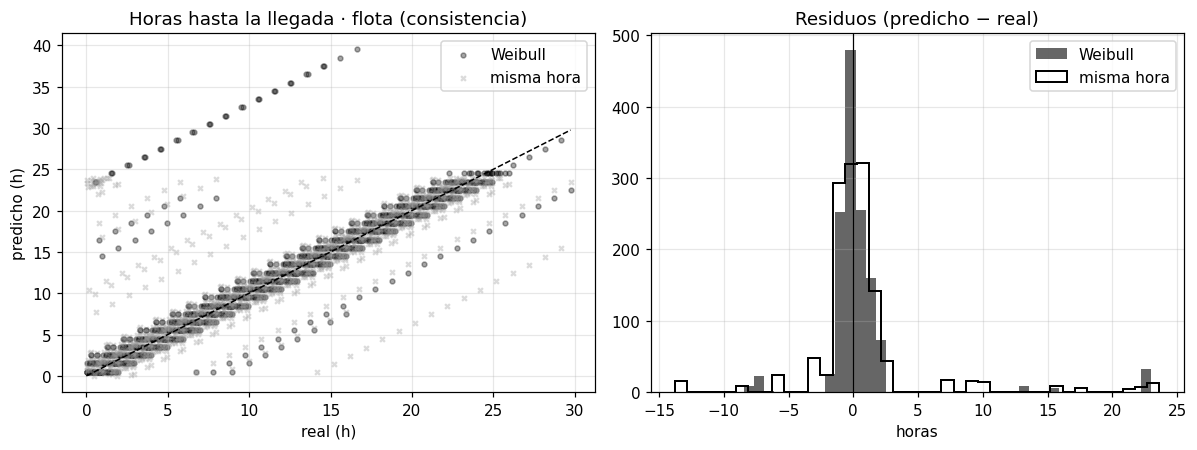

In [8]:
pp = pps["detector_f43"]
v = pp[(pp["nivel"] == "consistencia") & (pp["particion"] == "consistencia") & pp["km_moda"].notna() & pp["observado"]]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].scatter(v["t_obs_h"], v["weibull_moda"], s=10, c="k", alpha=0.35, label="Weibull")
axs[0].scatter(v["t_obs_h"], v["base_misma_hora"], s=10, c="0.6", marker="x", alpha=0.35, label="misma hora")
lim = [0, max(v["t_obs_h"].max(), 1)]
axs[0].plot(lim, lim, "k--", lw=1)
axs[0].set(title="Horas hasta la llegada · flota (consistencia)", xlabel="real (h)", ylabel="predicho (h)"); axs[0].legend()
axs[1].hist(v["weibull_moda"] - v["t_obs_h"], bins=40, color="0.25", alpha=0.8, label="Weibull")
axs[1].hist(v["base_misma_hora"] - v["t_obs_h"], bins=40, histtype="step", color="k", lw=1.3, label="misma hora")
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set(title="Residuos (predicho − real)", xlabel="horas"); axs[1].legend()
plt.tight_layout(); plt.show()

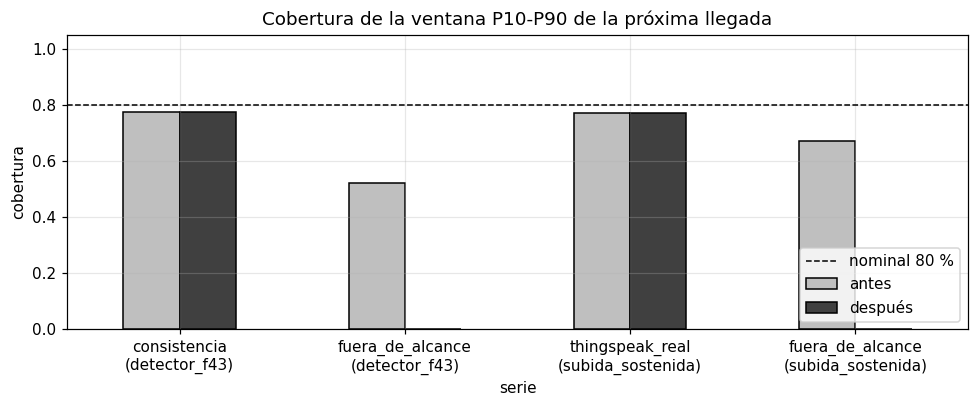

,antes,después
serie,,
consistencia\n(detector_f43),0.776,0.776
fuera_de_alcance\n(detector_f43),0.522,NaN
thingspeak_real\n(subida_sostenida),0.771,0.771
fuera_de_alcance\n(subida_sostenida),0.670,NaN


In [9]:
filas = []
for nombre in res["evaluacion"]:
    for nivel, b in res["evaluacion"][nombre].items():
        vt = b.get("ventana_p10_p90")
        if vt:
            filas.append({"serie": f"{nivel}\n({nombre})", "antes": vt["antes"]["cobertura"],
                          "después": vt.get("despues", {}).get("cobertura", np.nan)})
cob = pd.DataFrame(filas).set_index("serie")
ax = cob.plot.bar(color=["0.75", "0.25"], edgecolor="k", figsize=(9, 3.8), rot=0)
ax.axhline(0.8, color="k", ls="--", lw=1, label="nominal 80 %"); ax.set_ylim(0, 1.05)
ax.set(title="Cobertura de la ventana P10-P90 de la próxima llegada", ylabel="cobertura"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
display(cob.round(3))

## 6. En vivo (F7): últimas predicciones y pronóstico frente a real

La consulta `predicciones` del job de Spark (F7) aplica este mismo modelo versionado a cada micro-lote y escribe en
InfluxDB (measurement `predicciones`, `dimension = D4`). Se leen las últimas estimaciones y las verificaciones
(`tipo = verificacion`: el pronóstico comparado con lo que pasó de verdad en el instante objetivo). Los datos reales
están en el bucket `monitoraqua`; la flota extrapolada, en `monitoraqua_aumentados` (fechas simuladas 28-sep a 28-oct).

In [10]:
est = su.predicciones("D4", "estimacion", horas=48, limite=400)
if len(est):
    ult = est.sort_values("_time").groupby("sensorId").tail(1)
    cols = [c for c in ["_time", "sensorId", "version_modelo", *['horas_moda', 'ventana_ini_h', 'ventana_fin_h', 'prob_6h', 'prob_12h', 'prob_24h', 'modelo_tipo'], "advertencia"] if c in ult]
    display(ult[cols].reset_index(drop=True))
else:
    print("Sin estimaciones reales en las últimas 48 h")
mot = su.predicciones("D4", "motivo", horas=48, limite=400)
if len(mot):
    mot = mot.sort_values("_time").groupby("sensorId").tail(1)
    if len(est):   # vigente: solo si el tanque no tuvo una estimación posterior al motivo
        ult_est = est.groupby("sensorId")["_time"].max()
        mot = mot[mot["_time"] > mot["sensorId"].map(ult_est).fillna(pd.Timestamp(0, tz="America/Lima"))]
    print("Tanques reales donde hoy el modelo no aplica (motivo vigente):")
    display(mot[["_time", "sensorId", "motivo"]].reset_index(drop=True))

Sin estimaciones reales en las últimas 48 h
Tanques reales donde hoy el modelo no aplica (motivo vigente):


,_time,sensorId,motivo
0,2026-10-30 00:52:08-05:00,thingspeak-283977,sin modelo de llegadas para este tanque (pocas...
1,2026-10-30 01:00:54-05:00,thingspeak-480876,sin modelo de llegadas para este tanque (pocas...
2,2026-10-30 01:27:43-05:00,thingspeak-1233815,sin modelo de llegadas para este tanque (pocas...
3,2026-10-30 01:33:24.495000-05:00,esp32-tanque-real-01,sin modelo de llegadas para este tanque (pocas...
4,2026-10-30 01:33:59-05:00,thingspeak-3418755,fuera del alcance de D4: tanque de agua de llu...
5,2026-10-30 01:41:22-05:00,thingspeak-1233810,esperando la primera llegada observada en el s...


In [11]:
ver_real = su.predicciones("D4", "verificacion", horas=48)
ver_flota = su.predicciones("D4", "verificacion", bucket="monitoraqua_aumentados", horas=1440)
for nombre, v in (("real", ver_real), ("flota", ver_flota)):
    if len(v) and "llegada_real_ts" in v and "llegada_pred_ts" in v:
        v = v.dropna(subset=["llegada_real_ts", "llegada_pred_ts"])
        err = (v["llegada_real_ts"] - v["llegada_pred_ts"]) * 2.7777777777777776e-07
        r2 = "" if 2.7777777777777776e-07 != 1.0 else f" · R² {su.r2(v['llegada_real_ts'], v['llegada_pred_ts']):.3f}"
        print(f"{nombre}: {len(v)} pronósticos verificados · MAE en vivo {err.abs().mean():.3f} · "
              f"sesgo {(-err).mean():+.3f}{r2}")
        display(v.assign(_e=err.abs()).groupby("sensorId")["_e"].agg(verificados="count", MAE="mean").round(3))
    else:
        print(f"{nombre}: todavía sin verificaciones de D4 (ver docs/inferencia-en-vivo.md, pendientes)")

real: todavía sin verificaciones de D4 (ver docs/inferencia-en-vivo.md, pendientes)
flota: 108 pronósticos verificados · MAE en vivo 6.223 · sesgo +6.223


,verificados,MAE
sensorId,,
flota-zonaA-01,26,3.640
flota-zonaA-02,27,9.791
flota-zonaB-01,27,5.637
flota-zonaB-02,28,5.745


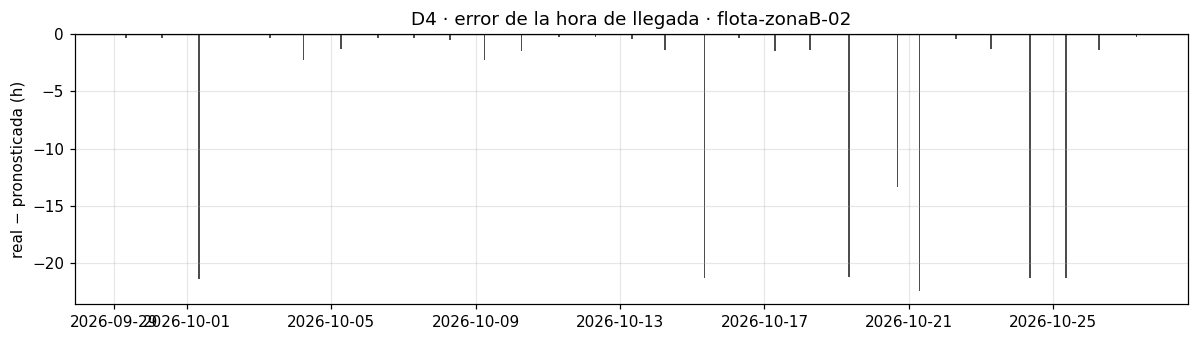

In [12]:
v = ver_flota if len(ver_flota) else ver_real
if len(v) and "llegada_real_ts" in v:
    v = v.dropna(subset=["llegada_real_ts", "llegada_pred_ts"])
    s = v["sensorId"].value_counts().index[0]
    g = v[v["sensorId"] == s].sort_values("_time")
    fig, ax = plt.subplots(figsize=(11, 3.2))
    if 2.7777777777777776e-07 != 1.0:   # D4: error de la hora de llegada en horas
        ax.bar(g["_time"], (g["llegada_real_ts"] - g["llegada_pred_ts"]) * 2.7777777777777776e-07, width=0.05, color="0.3")
        ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("real − pronosticada (h)")
    else:
        ax.plot(g["_time"], g["llegada_real_ts"], "k-", lw=1.2, label="real")
        ax.plot(g["_time"], g["llegada_pred_ts"], "--", color="0.45", lw=1.2, label="pronosticado (F7)"); ax.legend()
    ax.set_title(f"D4 · error de la hora de llegada · {s}"); plt.tight_layout(); plt.show()

## 7. Limitaciones (copiadas de `docs/modelo-d4.md`)

In [13]:
display(Markdown(su.secciones("modelo-d4.md", ['Limitaciones'])))

## 9. Limitaciones

- **El detector congelado f4.3 no ve los llenados de los canales nivelPct de ThingSpeak.** Por eso se usó la subida
  sostenida como complemento. En F7, si se quiere D4 para esos tanques, hay que detectar sus llenados con ese mismo
  criterio, porque el detector en vivo no los emite.
- **El único tanque real de la red evaluable es 1233810,** con solo 5 intervalos observados en la prueba y un sesgo
  de selección (29 % censurados, los intervalos más largos). Su resultado es indicativo.
- **3418755 (agua de lluvia) queda fuera del alcance de D4** y se reporta aparte.
- **A 24 h el modelo de la flota queda descalibrado** por un cambio de ritmo entre el entrenamiento y la evaluación.
- **ThingSpeak 480876 y 283977 no tienen modelo:** no tienen suficientes llegadas en el entrenamiento.
- **ESP32:** geometría provisional, llegadas falsas conocidas de f4.3, y su caudal no es confiable.
- **La flota es generada:** su regularidad (cada ~24 h, a las 5-7 h) es más alta que la de un servicio real. Por
  eso no es métrica final.
